In [1]:
from pyspark.sql import SparkSession

spark = SparkSession.builder \
    .appName("COVID19_RQ4_MapReduce") \
    .getOrCreate()

sc = spark.sparkContext

In [2]:
data_path = "../../covid.csv"

df = (
    spark.read
    .option("header", "true")
    .option("inferSchema", "true")
    .csv(data_path)
)

print("Number of records:", df.count())
df.printSchema()

Number of records: 10647
root
 |-- dateRep: string (nullable = true)
 |-- year_week: string (nullable = true)
 |-- cases_weekly: integer (nullable = true)
 |-- deaths_weekly: integer (nullable = true)
 |-- countriesAndTerritories: string (nullable = true)
 |-- geoId: string (nullable = true)
 |-- countryterritoryCode: string (nullable = true)
 |-- popData2019: integer (nullable = true)
 |-- continentExp: string (nullable = true)
 |-- rate_14d: double (nullable = true)



In [3]:
def mapper4(row):
    continent = row["continentExp"]
    cases = row["cases_weekly"]
    deaths = row["deaths_weekly"]

    if continent is None or cases is None or deaths is None:
        return None

    return (continent, (float(cases), float(deaths)))

In [4]:
def reducer4(a, b):
    total_cases = a[0] + b[0]
    total_deaths = a[1] + b[1]

    return (total_cases, total_deaths)

In [5]:
import time
start_time = time.time()

mapped = (
    df.select(
        "continentExp",
        "cases_weekly",
        "deaths_weekly"
    )
    .rdd
    .map(mapper4)
    .filter(lambda x: x is not None)
)

reduced = mapped.reduceByKey(reducer4)

results = reduced.collect()

end_time = time.time()

execution_time = end_time - start_time

print("MapReduce execution time: {:.4f} seconds".format(execution_time))

MapReduce execution time: 1.0776 seconds


In [19]:
from pyspark.sql.types import (
    StructType, StructField, StringType, DoubleType
)

schema = StructType([
    StructField("continent", StringType(), False),
    StructField("total_cases", DoubleType(), False),
    StructField("total_deaths", DoubleType(), False)
])

final_df = spark.createDataFrame(
    [
        (continent, totals[0], totals[1])
        for continent, totals in results
    ],
    schema
)

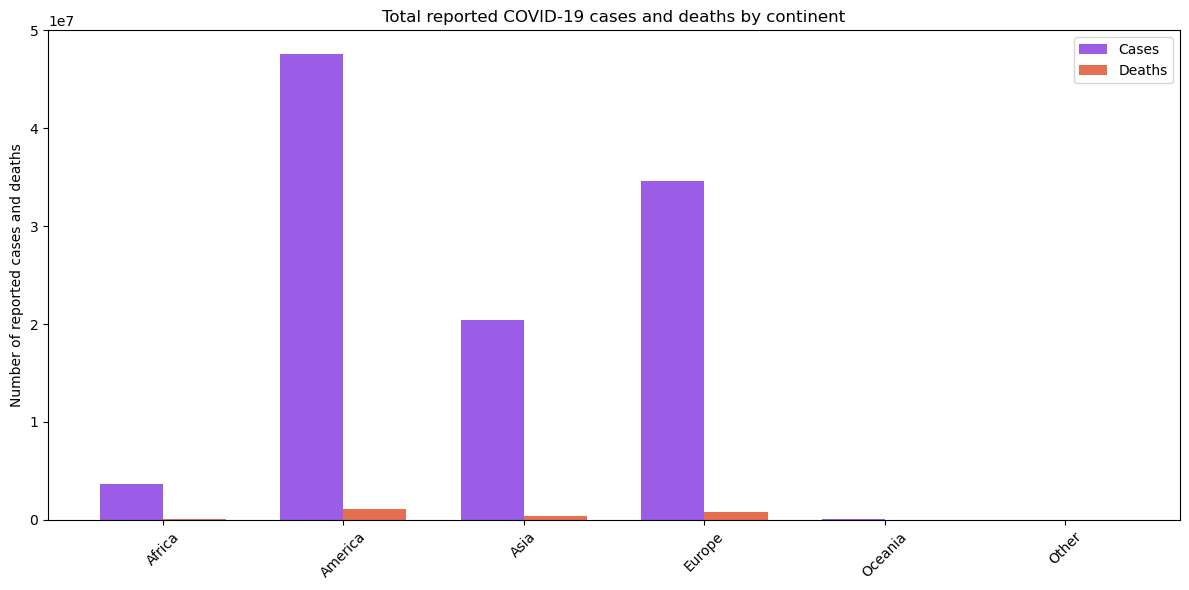

In [30]:
import matplotlib.pyplot as plt
import numpy as np

plot_df = final_df.toPandas().sort_values("continent")

x = np.arange(len(plot_df))
width = 0.35

fig, ax = plt.subplots(figsize=(12, 6))

ax.bar(
    x - width/2,
    plot_df["total_cases"],
    width,
    label="Cases",
    color="#9B5DE5"
)

ax.bar(
    x + width/2,
    plot_df["total_deaths"],
    width,
    label="Deaths",
    color="#E76F51"
)

ax.set_title("Total reported COVID-19 cases and deaths by continent")
ax.set_ylabel("Number of reported cases and deaths")
ax.set_xticks(x)
ax.set_xticklabels(plot_df["continent"], rotation=45)
ax.legend()

plt.tight_layout()
plt.show()


In [17]:
final_df = final_df.orderBy("continent").collect()

for row in final_df:
    print(
        "{}\t{}\t{}".format(
            row["continent"],
            row["total_cases"],
            row["total_deaths"]
        )
    )

Africa	3673181.0	95128.0
America	47620931.0	1107060.0
Asia	20438608.0	343886.0
Europe	34642469.0	775857.0
Oceania	57809.0	1210.0
Other	705.0	6.0
